# 04 - Validation des clusters

Objectif : mesurer la qualité des groupes (chapitre 4), tester la stabilité et choisir la meilleure solution.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gower
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score)
from kmodes.kprototypes import KPrototypes

import sys
sys.path.insert(0, "..")
import fonctions

X, y, Xa, Xb = fonctions.preparer()
numeriques, categorielles = fonctions.types_de_variables(X)
G = gower.gower_matrix(Xb)

## 1. Les indices du cours

Internes (sans la cible) :

- Silhouette : $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, plus grand = mieux
- Davies-Bouldin : $DB = \dfrac{1}{k}\sum_i \max_{j \neq i} \dfrac{\sigma_i + \sigma_j}{d_{ij}}$, plus petit = mieux
- Dunn : $D = \dfrac{\min \delta(C_i, C_j)}{\max \Delta(C_i)}$, plus grand = mieux

Externes (avec la cible y) :

- ARI : $\dfrac{RI - E[RI]}{\max(RI) - E[RI]}$
- NMI : $\dfrac{2 I(U;V)}{H(U) + H(V)}$
- V-mesure : $2 \cdot \dfrac{h \cdot c}{h + c}$ ($h$ = homogénéité, $c$ = complétude)

Silhouette et Dunn sont calculés sur Gower pour toutes les méthodes. Davies-Bouldin est calculé sur (a).

In [2]:
def evaluer(nom, groupes):
    # on ignore le bruit de DBSCAN (groupe -1)
    garder = groupes >= 0
    g = groupes[garder]
    G2 = G[garder][:, garder]
    y2 = y[garder]
    return {
        "méthode": nom,
        "k": len(np.unique(g)),
        "silhouette": silhouette_score(G2, g, metric="precomputed"),
        "davies_bouldin": davies_bouldin_score(Xa[garder], g),
        "dunn": fonctions.dunn(G2, g),
        "ARI": adjusted_rand_score(y2, g),
        "NMI": normalized_mutual_info_score(y2, g),
        "homogeneite": homogeneity_score(y2, g),
        "completude": completeness_score(y2, g),
        "V_mesure": v_measure_score(y2, g),
        "plus_petit_groupe": np.bincount(g).min(),
    }

## 2. Toutes les méthodes, pour k de 2 à 6

In [3]:
# préparations
Z10 = PCA(n_components=10, random_state=42).fit_transform(Xa)        # pour GMM
Xp = Xb.copy()
Xp[numeriques] = StandardScaler().fit_transform(Xp[numeriques])      # pour K-prototypes
positions_cat = [Xp.columns.get_loc(c) for c in categorielles]
G_vecteur = squareform(G, checks=False)
lien_single = linkage(G_vecteur, method="single")
lien_complete = linkage(G_vecteur, method="complete")
lien_average = linkage(G_vecteur, method="average")

resultats = []
for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xa)
    kmed = fonctions.kmedoids_meilleur(G, k)[0]
    kproto = KPrototypes(n_clusters=k, init="Cao", n_init=3, random_state=42).fit_predict(Xp.values, categorical=positions_cat)
    gmm = GaussianMixture(n_components=k, n_init=3, random_state=42).fit(Z10).predict(Z10)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xa)
    single = fcluster(lien_single, t=k, criterion="maxclust") - 1
    complete = fcluster(lien_complete, t=k, criterion="maxclust") - 1
    average = fcluster(lien_average, t=k, criterion="maxclust") - 1

    resultats.append(evaluer("K-means", kmeans))
    resultats.append(evaluer("K-medoids", kmed))
    resultats.append(evaluer("K-prototypes", kproto))
    resultats.append(evaluer("GMM", gmm))
    resultats.append(evaluer("CAH Ward", ward))
    resultats.append(evaluer("CAH single", single))
    resultats.append(evaluer("CAH complete", complete))
    resultats.append(evaluer("CAH average", average))
    print("k =", k, "terminé")

tableau = pd.DataFrame(resultats)

k = 2 terminé


k = 3 terminé


k = 4 terminé


k = 5 terminé


k = 6 terminé


In [4]:
# DBSCAN choisit lui-même le nombre de groupes (mêmes réglages que le notebook 03)
Z2 = PCA(n_components=2, random_state=42).fit_transform(Xa)
groupes_db = DBSCAN(eps=0.2, min_samples=4).fit_predict(Z2)
ligne_dbscan = evaluer("DBSCAN", groupes_db)
print(pd.Series(ligne_dbscan))

méthode                DBSCAN
k                          10
silhouette          -0.051725
davies_bouldin       2.064303
dunn                 0.013416
ARI                  0.068653
NMI                  0.024592
homogeneite          0.016759
completude           0.046174
V_mesure             0.024592
plus_petit_groupe           2
dtype: object


In [5]:
print("Silhouette :")
print(tableau.pivot(index="méthode", columns="k", values="silhouette").round(3))
print("\nDavies-Bouldin :")
print(tableau.pivot(index="méthode", columns="k", values="davies_bouldin").round(3))
print("\nDunn :")
print(tableau.pivot(index="méthode", columns="k", values="dunn").round(3))
print("\nARI :")
print(tableau.pivot(index="méthode", columns="k", values="ARI").round(3))
print("\nPlus petit groupe :")
print(tableau.pivot(index="méthode", columns="k", values="plus_petit_groupe"))

Silhouette :
k                 2      3      4      5      6
méthode                                        
CAH Ward      0.227  0.198  0.091  0.093  0.107
CAH average   0.274  0.148  0.124  0.128  0.103
CAH complete  0.164  0.125  0.110  0.111  0.108
CAH single    0.297  0.233  0.217  0.161  0.096
GMM           0.223  0.177  0.099  0.092  0.131
K-means       0.227  0.173  0.189  0.164  0.163
K-medoids     0.151  0.133  0.107  0.108  0.105
K-prototypes  0.226  0.115  0.113  0.103  0.082

Davies-Bouldin :
k                 2      3      4      5      6
méthode                                        
CAH Ward      1.959  1.823  1.895  1.941  2.263
CAH average   1.054  0.979  2.115  1.998  2.016
CAH complete  2.549  2.599  3.207  3.114  3.287
CAH single    0.513  0.499  0.665  0.620  0.697
GMM           1.971  2.536  3.202  2.961  2.234
K-means       1.946  2.016  2.394  2.139  1.972
K-medoids     3.131  3.171  3.571  3.640  3.495
K-prototypes  1.951  1.885  1.916  1.744  2.014

Dunn :
k

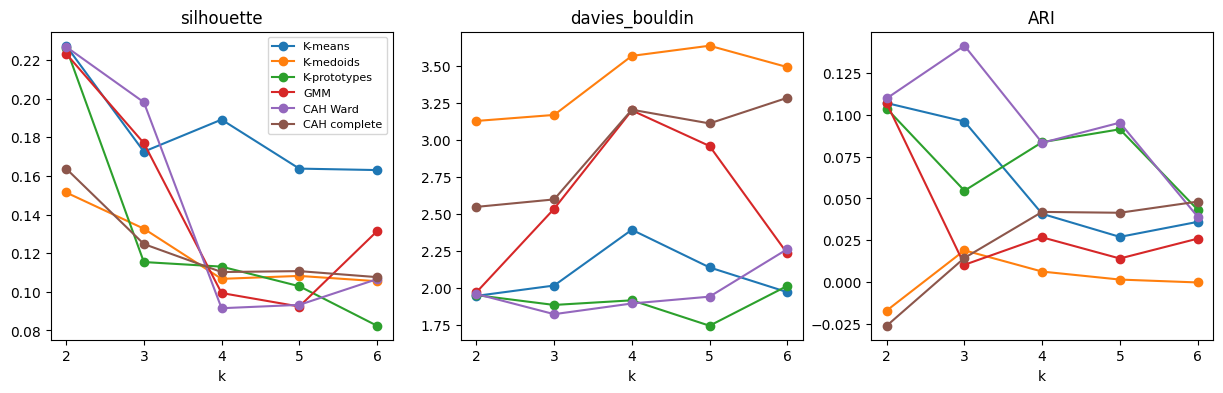

In [6]:
methodes = ["K-means", "K-medoids", "K-prototypes", "GMM", "CAH Ward", "CAH complete"]
indices = ["silhouette", "davies_bouldin", "ARI"]

plt.figure(figsize=(15, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    for m in methodes:
        lignes = tableau[tableau["méthode"] == m]
        plt.plot(lignes["k"], lignes[indices[i]], marker="o", label=m)
    plt.xlabel("k")
    plt.xticks(range(2, 7))
    plt.title(indices[i])
plt.subplot(1, 3, 1)
plt.legend(fontsize=8)
plt.show()

## 3. Stabilité de K-means (k = 3)

1. On relance K-means 20 fois avec une seule initialisation et des graines différentes.
2. On fait 20 tirages bootstrap (avec remise) des clients.

On compare les résultats avec l'ARI : proche de 1 = stable.

In [7]:
# 1) 20 graines, une seule initialisation
lancements = []
for graine in range(20):
    lancements.append(KMeans(n_clusters=3, n_init=1, random_state=graine).fit_predict(Xa))

ari_graines = []
for i in range(20):
    for j in range(i + 1, 20):
        ari_graines.append(adjusted_rand_score(lancements[i], lancements[j]))

# 2) 20 tirages bootstrap
reference = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xa)
rng = np.random.default_rng(42)
ari_bootstrap = []
for b in range(20):
    tirage = rng.choice(len(Xa), len(Xa), replace=True)
    modele = KMeans(n_clusters=3, n_init=10, random_state=b).fit(Xa[tirage])
    ari_bootstrap.append(adjusted_rand_score(reference.labels_, modele.predict(Xa)))

print("Graines : ARI moyen", round(np.mean(ari_graines), 3), "minimum", round(np.min(ari_graines), 3))
print("Bootstrap : ARI moyen", round(np.mean(ari_bootstrap), 3), "minimum", round(np.min(ari_bootstrap), 3))

Graines : ARI moyen 0.572 minimum 0.353
Bootstrap : ARI moyen 0.951 minimum 0.648


Avec une seule initialisation, K-means tombe dans des optimums locaux différents. Avec n_init=10, il est stable.

## 4. Stabilité de la CAH Ward (k = 3)

Ward n'utilise pas le hasard : on teste seulement le bootstrap, sur les clients tirés.

Ward : ARI moyen 0.962 minimum 0.883


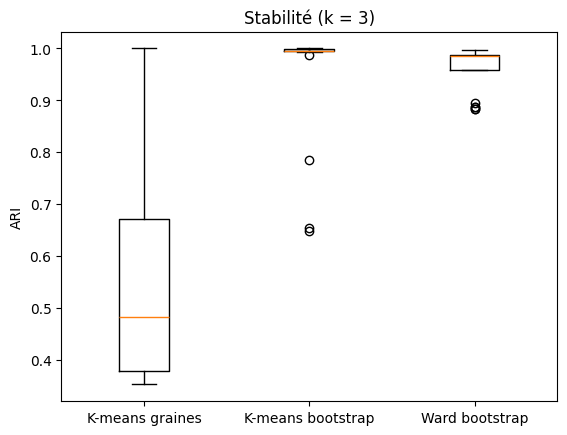

In [8]:
ward_ref = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xa)
ari_ward = []
for b in range(20):
    clients = np.unique(rng.choice(len(Xa), len(Xa), replace=True))   # environ 63 % des clients
    groupes = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xa[clients])
    ari_ward.append(adjusted_rand_score(ward_ref[clients], groupes))

print("Ward : ARI moyen", round(np.mean(ari_ward), 3), "minimum", round(np.min(ari_ward), 3))

plt.boxplot([ari_graines, ari_bootstrap, ari_ward])
plt.xticks([1, 2, 3], ["K-means graines", "K-means bootstrap", "Ward bootstrap"])
plt.ylabel("ARI")
plt.title("Stabilité (k = 3)")
plt.show()

## 5. Choix de la solution

1. On enlève les solutions avec un groupe de moins de 2 % des clients (80).
2. On garde k = 3 ou 4 : le sujet demande une recommandation par segment.
3. On classe par silhouette, puis on regarde Davies-Bouldin et ARI.

In [9]:
candidats = tableau[(tableau["plus_petit_groupe"] >= 80) & (tableau["k"] >= 3) & (tableau["k"] <= 4)]
candidats = candidats.sort_values("silhouette", ascending=False)
candidats[["méthode", "k", "silhouette", "davies_bouldin", "dunn", "ARI", "plus_petit_groupe"]].round(3).head(6)

,méthode,k,silhouette,davies_bouldin,dunn,ARI,plus_petit_groupe
12,CAH Ward,3,0.198,1.823,0.045,0.141,257
16,K-means,4,0.189,2.394,0.018,0.041,570
11,GMM,3,0.177,2.536,0.036,0.010,1270
8,K-means,3,0.173,2.016,0.020,0.096,570
9,K-medoids,3,0.133,3.171,0.008,0.019,1004
14,CAH complete,3,0.125,2.599,0.064,0.014,384


In [10]:
segments = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xa)
print("Solution retenue : CAH Ward, k = 3")
print("Tailles :", np.bincount(segments))

Solution retenue : CAH Ward, k = 3
Tailles : [2617 1126  257]


Conclusion : la CAH Ward avec k = 3 a la meilleure silhouette, le meilleur Davies-Bouldin et le meilleur ARI parmi les candidats, et elle est stable. Seul Dunn préfère CAH complete. Les indices restent faibles : les groupes se chevauchent.